### Iowa fatal crash data statistics and visualization

- Reads Iowa crash data for a given year (or a range of years) from 2014 to 2024 into a pandas dataframe
- Does summary statistics on some columns and plots them
- visualizes the data on a map

## Data

 The 43 fields below are the ones present in **every** year, so they are safe to use when combining years. They hold numeric codes only

**Identification**

| Field | Meaning |
|---|---|
| `STATE` | State FIPS code (always 19 = Iowa) |
| `ST_CASE` | Case number for the crash, unique within a year (190001, 190002, ...) |
| `YEAR` | Crash year (2014-2024) |

**When**

| Field | Meaning |
|---|---|
| `MONTH`, `DAY`, `DAY_WEEK` | Month, day of month, day of week (1 = Sunday) |
| `HOUR`, `MINUTE` | Time of the crash (24-hour clock; 99 = unknown) |
| `NOT_HOUR`, `NOT_MIN` | Time EMS was notified |
| `ARR_HOUR`, `ARR_MIN` | Time EMS arrived at the scene |
| `HOSP_HR`, `HOSP_MN` | Time EMS arrived at the hospital |

**Where**

| Field | Meaning |
|---|---|
| `LATITUDE`, `LONGITUD` | Crash location in decimal degrees (note the spelling `LONGITUD`) |
| `COUNTY` | County code |
| `CITY` | City code (0 = not in a city) |
| `TWAY_ID`, `TWAY_ID2` | Name or number of the trafficway; `TWAY_ID2` is the second road at an intersection and is often empty |
| `ROUTE` | Route signing (interstate, US highway, state, county, ...) |
| `NHS` | 1 if the road is on the National Highway System |
| `MILEPT` | Milepoint along the route |
| `SP_JUR` | Special jurisdiction (e.g. military or park land) |
| `RAIL` | Railroad grade crossing ID (`0000000` = none) |

**Crash circumstances**

| Field | Meaning |
|---|---|
| `HARM_EV` | First harmful event (collision with a vehicle, tree, pedestrian, rollover, ...) |
| `MAN_COLL` | Manner of collision (front-to-rear, angle, ...) |
| `TYP_INT` | Type of intersection |
| `REL_ROAD` | Where the first harmful event happened relative to the road (on roadway, shoulder, median, ...) |
| `RELJCT1`, `RELJCT2` | Whether the crash was in an interchange area, and its location relative to a junction |
| `WEATHER` | Atmospheric conditions (clear, rain, snow, fog, ...) |
| `LGT_COND` | Light condition (daylight, dark, dusk, ...) |
| `WRK_ZONE` | Work zone type (0 = not in a work zone) |
| `SCH_BUS` | 1 if a school-bus-related vehicle was involved |

**People and vehicles**

| Field | Meaning |
|---|---|
| `FATALS` | Number of people killed |
| `PERSONS` | Total people involved |
| `PERMVIT` | People in motor vehicles in transport |
| `PERNOTMVIT` | People not in motor vehicles (pedestrians, cyclists, ...) |
| `PEDS` | Pedestrians involved |
| `VE_TOTAL` | Total vehicles involved |
| `VE_FORMS` | Vehicles in transport |
| `PVH_INVL` | Parked or working vehicles involved |


In [1]:
import pandas as pd
import folium
import os

# read in all years
DATA_FILE = "Iowa_crashes/iowa_fars_2014_2024.json"
df = pd.read_json(DATA_FILE)

print(f"{len(df)} crashes loaded")
df[["YEAR", "DAY_WEEK", "COUNTY","ST_CASE", "MONTH", "DAY", "HOUR", "FATALS", "LATITUDE", "LONGITUD"]].head()

3428 crashes loaded


,YEAR,DAY_WEEK,COUNTY,ST_CASE,MONTH,DAY,HOUR,FATALS,LATITUDE,LONGITUD
0,2014,5,13,190001,1,2,14,1,42.512269,-92.361803
1,2014,6,65,190002,1,10,8,4,43.036419,-91.615703
2,2014,5,169,190003,1,9,17,1,42.034386,-93.594328
3,2014,6,95,190004,1,10,16,1,41.768958,-92.065086
4,2014,6,117,190005,1,10,18,1,40.963319,-93.470831


In [38]:
# add text weather
# you could plot what weather has the most fatalities 
WEATHER_NAMES = {
    1: "Clear", 2: "Rain", 3: "Sleet or Hail", 4: "Snow",
    5: "Fog, Smog, Smoke", 6: "Severe Crosswinds",
    7: "Blowing Sand, Soil, Dirt", 8: "Other", 10: "Cloudy",
    11: "Blowing Snow", 12: "Freezing Rain or Drizzle",
    98: "Not Reported", 99: "Reported as Unknown",
}

df["WEATHERNAME"] = df["WEATHER"].map(WEATHER_NAMES).fillna("Unknown")
df["WEATHERNAME"].value_counts()

WEATHERNAME
Clear                       2402
Cloudy                       613
Rain                         160
Snow                          83
Fog, Smog, Smoke              59
Reported as Unknown           41
Freezing Rain or Drizzle      30
Severe Crosswinds             15
Blowing Snow                   9
Other                          5
Blowing Sand, Soil, Dirt       5
Not Reported                   3
Sleet or Hail                  3
Name: count, dtype: int64

In [39]:
# resolve the TYP_INT into words
INT_TYPES = {
    1: "Not an intersection", 2: "Four-way", 3: "T-intersection",
    4: "Y-intersection", 5: "Traffic circle", 6: "Roundabout",
    7: "Five-point or more", 10: "L-intersection",
    11: "Other intersection", 98: "Not Reported", 99: "Unknown",
}

df["INTERSECTION_TYPE"] = df["TYP_INT"].map(INT_TYPES).fillna("Unknown")
df["INTERSECTION_TYPE"].value_counts()

INTERSECTION_TYPE
Not an intersection    2506
Four-way                648
T-intersection          231
Y-intersection           24
L-intersection            8
Five-point or more        4
Other intersection        3
Roundabout                3
Not Reported              1
Name: count, dtype: int64

In [43]:
LIGHT_NAMES = {
    1: "Daylight", 2: "Dark - Not Lighted", 3: "Dark - Lighted", 4: "Dawn",
    5: "Dusk", 6: "Dark - Unknown Lighting", 7: "Other",
    8: "Not Reported", 9: "Reported as Unknown",
}

df["LIGHTNAME"] = df["LGT_COND"].map(LIGHT_NAMES).fillna("Unknown")

df["LIGHTNAME"].value_counts()



LIGHTNAME
Daylight                   1862
Dark - Not Lighted          966
Dark - Lighted              361
Dusk                        118
Dawn                         79
Reported as Unknown          22
Dark - Unknown Lighting      19
Not Reported                  1
Name: count, dtype: int64

In [42]:
# Manner of collision
MANNER_NAMES = {
    0: "Not a collision with motor vehicle", 1: "Front-to-Rear",
    2: "Front-to-Front", 6: "Angle", 7: "Sideswipe - Same Direction",
    8: "Sideswipe - Opposite Direction", 9: "Rear-to-Side",
    10: "Rear-to-Rear", 11: "Other", 98: "Not Reported", 99: "Reported as Unknown",
}

df["MANNERNAME"] = df["MAN_COLL"].map(MANNER_NAMES).fillna("Unknown")
df["MANNERNAME"].value_counts()


MANNERNAME
Not a collision with motor vehicle    1939
Angle                                  741
Front-to-Front                         401
Front-to-Rear                          252
Sideswipe - Same Direction              39
Sideswipe - Opposite Direction          34
Other                                   12
Reported as Unknown                      4
Rear-to-Side                             4
Not Reported                             2
Name: count, dtype: int64

Do some stats with the data and make plots

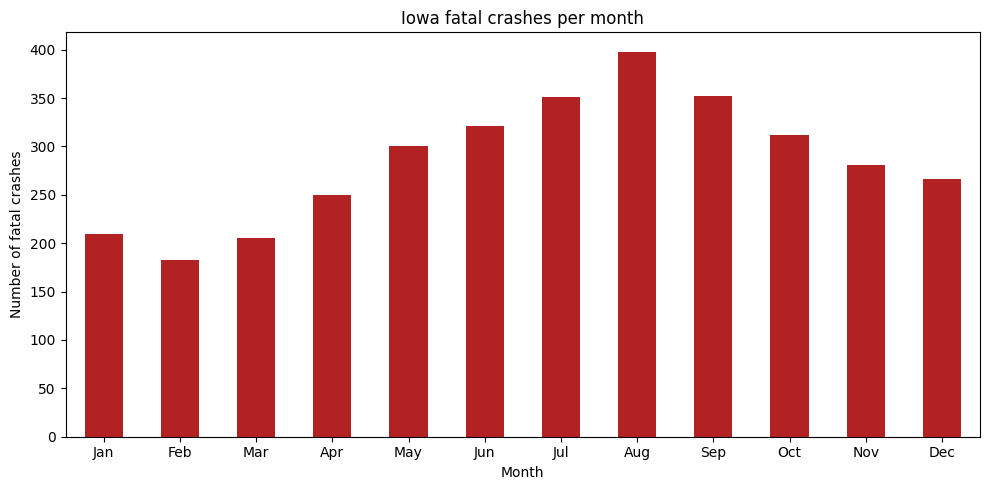

In [2]:
import matplotlib.pyplot as plt

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
per_month = df["MONTH"].value_counts().sort_index()

ax = per_month.plot(kind="bar", figsize=(10, 5), color="firebrick")
ax.set_xticklabels(month_names, rotation=0)
ax.set_xlabel("Month")
ax.set_ylabel("Number of fatal crashes")
ax.set_title("Iowa fatal crashes per month")
plt.tight_layout()
plt.show()


### Plot data
- Make sure each data point has a valid lat/long

In [3]:
df["LATITUDE"] = pd.to_numeric(df["LATITUDE"], errors="coerce")
df["LONGITUD"] = pd.to_numeric(df["LONGITUD"], errors="coerce")

# Rough bounding box around Iowa
valid = df["LATITUDE"].between(40.3, 43.6) & df["LONGITUD"].between(-96.7, -90.1)
print(f"Dropping {(~valid).sum()} crashes without a valid Iowa location")
crashes = df[valid].copy()
len(crashes)

Dropping 2 crashes without a valid Iowa location


3426

Draw on map using folium

In [4]:
iowa_center = [42.0, -93.5]
m = folium.Map(location=iowa_center, zoom_start=7, tiles="OpenStreetMap")

for row in crashes.itertuples():
    folium.CircleMarker(
        location=[row.LATITUDE, row.LONGITUD],
        radius=3,
        color="red",
        weight=1,
        fill=True,
        fill_color="red",
        fill_opacity=0.6,
    ).add_to(m)

m

Fatal crashes by Years (2014 - 2024)

In [5]:
year_counts = df["YEAR"].value_counts().sort_index()

print(year_counts)

YEAR
2014    288
2015    282
2016    355
2017    301
2018    291
2019    313
2020    310
2021    329
2022    305
2023    330
2024    324
Name: count, dtype: int64


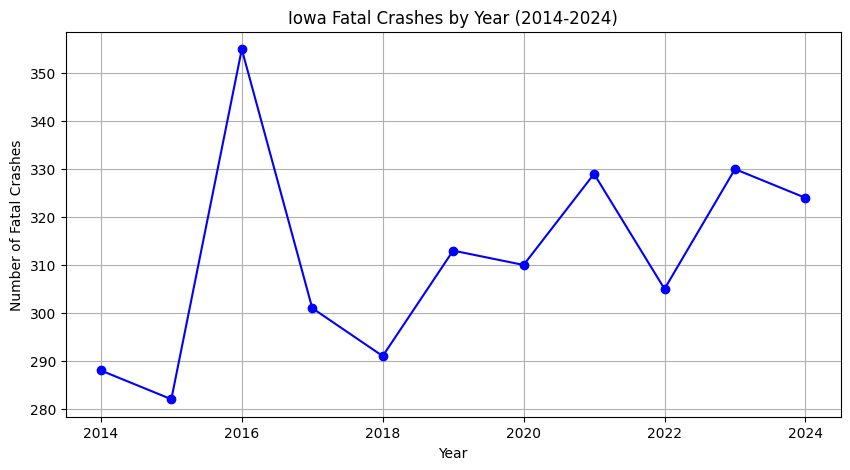

In [6]:
year_counts.plot(
    kind="line",
    marker="o",
    color="blue",
    figsize=(10,5),
    title="Iowa Fatal Crashes by Year (2014-2024)"
)

plt.xlabel("Year")
plt.ylabel("Number of Fatal Crashes")
plt.grid(True)

plt.show()

Fatal Crasheees by county 

In [7]:
iowa_counties = [
    "Adair","Adams","Allamakee","Appanoose","Audubon","Benton","Black Hawk","Boone","Bremer",
    "Buchanan","Buena Vista","Butler","Calhoun","Carroll","Cass","Cedar","Cerro Gordo","Cherokee",
    "Chickasaw","Clarke","Clay","Clayton","Clinton","Crawford","Dallas","Davis","Decatur","Delaware",
    "Des Moines","Dickinson","Dubuque","Emmet","Fayette","Floyd","Franklin","Fremont","Greene",
    "Grundy","Guthrie","Hamilton","Hancock","Hardin","Harrison","Henry","Howard","Humboldt","Ida",
    "Iowa","Jackson","Jasper","Jefferson","Johnson","Jones","Keokuk","Kossuth","Lee","Linn","Louisa",
    "Lucas","Lyon","Madison","Mahaska","Marion","Marshall","Mills","Mitchell","Monona","Monroe",
    "Montgomery","Muscatine","O'Brien","Osceola","Page","Palo Alto","Plymouth","Pocahontas","Polk",
    "Pottawattamie","Poweshiek","Ringgold","Sac","Scott","Shelby","Sioux","Story","Tama","Taylor",
    "Union","Van Buren","Wapello","Warren","Washington","Wayne","Webster","Winnebago","Winneshiek",
    "Woodbury","Worth","Wright",
]
COUNTY_NAMES = {2 * i + 1: name for i, name in enumerate(iowa_counties)}

df["COUNTYNAME"] = df["COUNTY"].map(COUNTY_NAMES).fillna("Unknown")

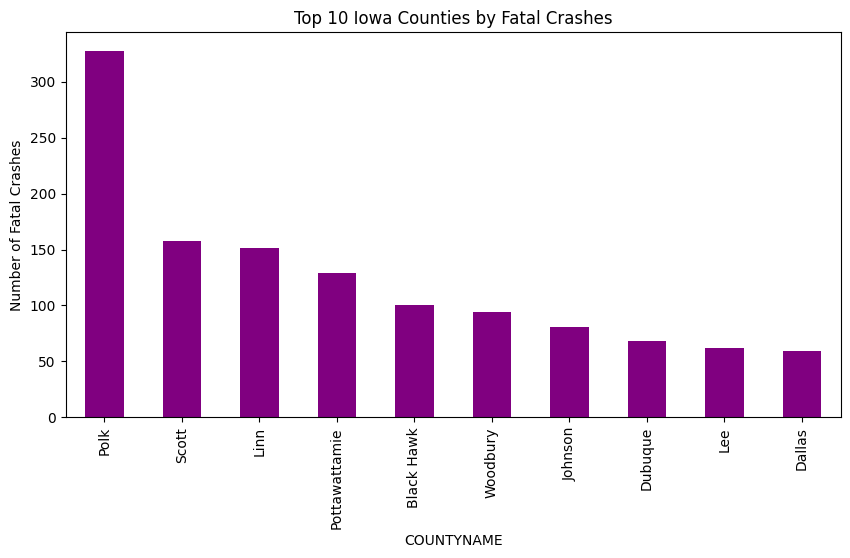

In [8]:
county_counts = df["COUNTYNAME"].value_counts().head(10)

county_counts.plot(
    kind="bar",
    figsize=(10,5),
    color="purple",
    title="Top 10 Iowa Counties by Fatal Crashes"
)

plt.ylabel("Number of Fatal Crashes")
plt.show()

At what time of day do fatal crashes occur most often?

In [9]:
# HOUR = 0-23; 99 means "unknown" in FARS, so drop it
hour_counts = (
    df.loc[df["HOUR"] <= 23, "HOUR"]
    .value_counts()
    .reindex(range(24), fill_value=0)
    .sort_index()
)

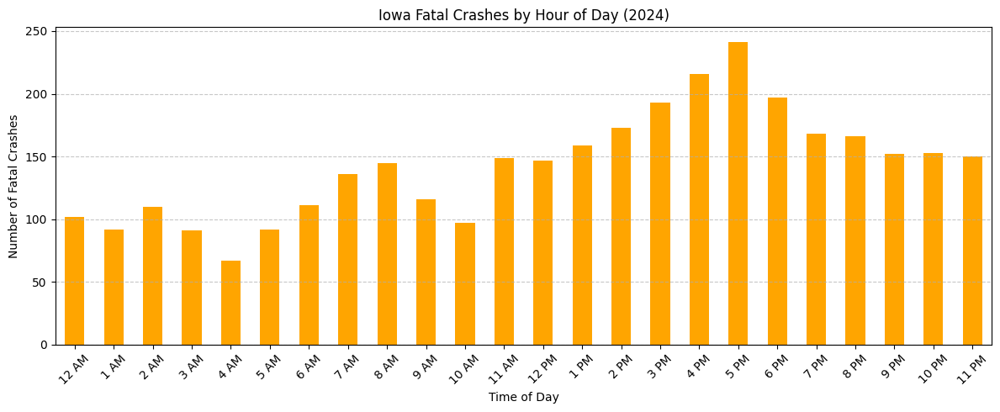

In [10]:
hour_labels = [
    "12 AM","1 AM","2 AM","3 AM","4 AM","5 AM",
    "6 AM","7 AM","8 AM","9 AM","10 AM","11 AM",
    "12 PM","1 PM","2 PM","3 PM","4 PM","5 PM",
    "6 PM","7 PM","8 PM","9 PM","10 PM","11 PM"
]

hour_counts.plot(
    kind="bar",
    figsize=(12,5),
    color="orange",
    title="Iowa Fatal Crashes by Hour of Day (2024)"
)

plt.xticks(range(24), hour_labels, rotation=45)
plt.xlabel("Time of Day")
plt.ylabel("Number of Fatal Crashes")
plt.tight_layout()
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

In [11]:
print(crashes[["LATITUDE", "LONGITUD"]].head())
print(crashes[["LATITUDE", "LONGITUD"]].shape)

    LATITUDE   LONGITUD
0  42.512269 -92.361803
1  43.036419 -91.615703
2  42.034386 -93.594328
3  41.768958 -92.065086
4  40.963319 -93.470831
(3426, 2)


Day and Night crashes comparison map

In [ ]:
# CH you could first print out the number of day vs night crashes (per year)

In [14]:
import folium

iowa_center = [42.0, -93.5]
m = folium.Map(location=iowa_center, zoom_start=7)

for row in crashes.itertuples():

    if 6 <= row.HOUR < 18:
        color = "orange"   # Day
    else:
        color = "blue"     # Night

    folium.CircleMarker(
        location=[row.LATITUDE, row.LONGITUD],
        radius=3,
        color=color,
        fill=True,
        fill_color=color
    ).add_to(m)

m

In [ ]:
import pandas as pd

df = pd.read_json("iowa_crashes/iowa_fars_2014_2024.json")
print(df.shape)

(3428, 43)


The number of crashes at each location

In [ ]:
# CH you could show a table with how many fatalities where 1, 2, 3 etc. 
# also put more data into your popup, e.g. 

In [18]:
crash_counts = (
    df.groupby(["LATITUDE", "LONGITUD"])
      .size()
      .reset_index(name="Crash_Count")
)

m = folium.Map(location=[42.0, -93.5], zoom_start=7)

for _, row in crash_counts.iterrows():

    count = row["Crash_Count"]

    folium.CircleMarker(
        location=[row["LATITUDE"], row["LONGITUD"]],
        radius=count * count * 2 , # make 2 and 3 much larger than 1 
        color="red",
        fill=True,
        fill_color="red",
        fill_opacity=0.6,
        popup=f"Crashes: {count}"
    ).add_to(m)

m

Representing color-coded information for different number fatalities. Red being higher and green being lower

CH: generally just using the marker size does not seem to be an effective approach for visualizing 1 vs 2 vs >=3 (just and observation, leave it in !)

In [ ]:
# using color and size
import pandas as pd
import folium

m = folium.Map(
    location=[42.0, -93.5],
    zoom_start=7,
    tiles="OpenStreetMap",
    prefer_canvas=True,                 # draws markers on one canvas instead of 3,400 SVG elements
)

for _, row in df.iterrows():

    if pd.notna(row["LATITUDE"]) and pd.notna(row["LONGITUD"]):

        fatalities = row["FATALS"]

        # Choose color
        if fatalities >= 3:
            color = "red"
        elif fatalities == 2:
            color = "orange"
        else:
            color = "green"

        folium.CircleMarker(
            location=[row["LATITUDE"], row["LONGITUD"]],
            radius=fatalities * 3,
            color=color,
            fill=True,
            fill_color=color,
            tooltip=f"Fatalities: {fatalities}"
        ).add_to(m)

m

Heat map to identify crash hotspots across the Iowa State. 

In [47]:
import folium
from folium.plugins import HeatMap

df_map = df.dropna(subset=["LATITUDE", "LONGITUD"])
m = folium.Map(location=[42.0, -93.5], zoom_start=7, tiles="OpenStreetMap")

# create heatmap
heat_data = df_map[
    ["LATITUDE", "LONGITUD", "FATALS"]
].values.tolist()

HeatMap(
    heat_data,
    radius=12,
    blur=10,
    min_opacity=0.3  # make a bit transparent
).add_to(m)

m